# SIMULATION_2026 — La saison de Ligue des champions de Maxime

**Branche : `feature/simulation`.** On simule 10 000 saisons 2026-2027 à partir des
36 Elo de départ, du calendrier de 144 matchs et du modèle de Poisson de Moussa.
Chaque club reçoit une probabilité d’atteindre chaque tour, jusqu’au titre.

Ce travail suit **les consignes du groupe**, y compris leurs simplifications des
règles UEFA. Il ne prédit pas un vainqueur certain. Il n’utilise aucun vrai résultat
2026-2027 : la prévision se place avant le 8 septembre 2026.

**Pour lancer :** depuis `analyse/`, `Kernel → Restart & Run All`. Les dépendances sont
`numpy`, `pandas`, `matplotlib`, `joblib` et `scikit-learn` (backtest).
Les entrées sont produites par `v2_elo`, `v2_joueurs`, `v2_fatigue`, `v2_participants`,
`EDA_v2`, puis `MODEL_POISSON`. Le notebook du modèle est récupéré depuis
`feature/model-baseline` (version `65741bd`). Ses sources ne sont pas modifiées ici.

## 1. Diagnostic avant de coder

| Question | Choix |
|---|---|
| Cible | Atteindre un tour ; la simulation utilise des scores, pas seulement des vainqueurs |
| Variables connues à temps | Elo avant compétition, terrain et format ; calendrier connu |
| Fuites à éviter | Elo après le match, vrais scores de la saison simulée, modèle entraîné sur le backtest |
| Évaluation | Saisons 2024-2025 et 2025-2026, modèle réentraîné sur les saisons strictement antérieures |
| Baseline | Même probabilité pour les 36 clubs : 8/36 pour les quarts, 1/36 pour le titre |
| Métriques | Brier par tour (plus bas = mieux), vrais quart-de-finalistes parmi les huit favoris |
| Reproductibilité | Une graine fixe, 2026 ; mêmes entrées et même ordre d’exécution |

Trois points résolus avant le code : le modèle est disponible sur `feature/model-baseline` ;
la version des règles retenue est celle des consignes du groupe ; la finale 2026 absente
ne sera pas inventée dans le backtest. L’évaluation mesure la qualité de cette reconstruction
historique, elle ne constitue pas une preuve de réussite sur les prochaines saisons.

In [1]:
from pathlib import Path
from collections import Counter
from math import factorial
import ast
import hashlib
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import PoissonRegressor
from IPython.display import display, Markdown

RACINE = Path('..') if Path('../data/games.csv').is_file() else Path('.')
DATA, OUT = RACINE / 'data', RACINE / 'output'
NB_SIMULATIONS = 10_000
NB_BACKTEST = 10_000
GRAINE = 2026
REGLES = 'consignes_groupe'
assert NB_SIMULATIONS >= 10_000 and NB_BACKTEST >= 10_000

requis = {
    'modele_scores.joblib': 'MODEL_POISSON.ipynb',
    'calendrier_2026.csv': 'v2_participants.ipynb',
    'elo_participants_2026.csv': 'v2_elo.ipynb',
    'eda_matchs_c1.csv': 'EDA_v2.ipynb',
}
manquants = [f'{f} → lancer {notebook}' for f, notebook in requis.items() if not (OUT / f).is_file()]
if manquants:
    raise FileNotFoundError('Entrées absentes : ' + '; '.join(manquants))
if not (DATA / 'games.csv').is_file():
    raise FileNotFoundError('data/games.csv est nécessaire au calendrier historique du backtest.')

# Fichier généré localement par le notebook du groupe ; ne pas charger un joblib externe.
p = joblib.load(OUT / 'modele_scores.joblib')
cles = {'intercept', 'coef_ecart_100', 'coef_terrain', 'coef_nouveau_format', 'max_buts', 'variables'}
assert isinstance(p, dict) and cles <= set(p)
assert p['type'] == 'poisson'
assert p['variables'] == ['ecart_elo_complet', 'domicile', 'nouveau_format'], 'Le modèle a changé : adapter la simulation.'
assert np.isfinite([p[k] for k in ['intercept', 'coef_ecart_100', 'coef_terrain', 'coef_nouveau_format']]).all()
calendrier = pd.read_csv(OUT / 'calendrier_2026.csv', parse_dates=['date'], encoding='utf-8-sig')
elos = pd.read_csv(OUT / 'elo_participants_2026.csv', encoding='utf-8-sig')
assert len(calendrier) == 288 and len(elos) == 36 and elos.club_id.is_unique
clubs = (calendrier[['club_id', 'nom_uefa']].drop_duplicates().sort_values('club_id').reset_index(drop=True))
assert len(clubs) == 36 and clubs.club_id.is_unique
assert set(clubs.club_id) == set(elos.club_id)
elo_initial = clubs.club_id.map(elos.set_index('club_id').elo_complet).to_numpy(float)
assert np.isfinite(elo_initial).all()
assert calendrier.date.min() == pd.Timestamp('2026-09-08')
assert calendrier.date.max() == pd.Timestamp('2027-01-27')

historique = pd.read_csv(OUT / 'eda_matchs_c1.csv', parse_dates=['date'], encoding='utf-8-sig')
jeux = pd.read_csv(DATA / 'games.csv', parse_dates=['date'])
assert historique.game_id.is_unique and jeux.game_id.is_unique
assert historique.season.max() < 2026 and historique.date.max() < calendrier.date.min()
assert historique[['dom_j_buts_pour', 'ext_j_buts_pour']].notna().all().all()
assert historique.neutre.dtype == bool
print(f'{len(clubs)} clubs ; {len(calendrier) // 2} matchs ; {len(historique):,} matchs historiques.')
print('Modèle entraîné sur :', p.get('entraine_sur', 'non précisé'))
display(clubs.assign(elo_initial=elo_initial).sort_values('elo_initial', ascending=False).head(10))

36 clubs ; 144 matchs ; 1,871 matchs historiques.
Modèle entraîné sur : 2012-2025 (1871 matchs)


,club_id,nom_uefa,elo_initial
0,11,Arsenal,2025.0
15,281,Man City,1989.0
4,27,Bayern München,1972.0
10,131,FC Barcelona,1970.0
7,46,Inter,1943.0
20,418,Real Madrid,1932.0
23,583,Paris,1920.0
5,31,Liverpool,1895.0
27,985,Man United,1889.0
18,405,Aston Villa,1860.0


## 2. Les quatre fonctions officielles du modèle

Ces fonctions sont **copiées telles quelles** depuis la section 10 de `MODEL_POISSON`.
Les scores sont tirés dans la loi de Poisson complète : ils ne sont pas plafonnés à 10.
Seule la matrice destinée aux probabilités théoriques est tronquée et renormalisée.
Toutes les simulations passent explicitement leur générateur `rng`.

In [2]:
def buts_attendus(p, ecart_elo, domicile=1, minutes=90, nouveau_format=1):
    # Buts attendus (équipe qui reçoit, équipe qui se déplace)
    niveau = p['intercept'] + p['coef_nouveau_format'] * nouveau_format
    z = p['coef_ecart_100'] * ecart_elo / 100 + p['coef_terrain'] * domicile
    duree = minutes / 90
    return float(np.exp(niveau + z) * duree), float(np.exp(niveau - z) * duree)

def matrice_scores(p, ecart_elo, domicile=1, minutes=90):
    # m[i, j] = probabilité que l'équipe qui reçoit marque i buts et l'autre j
    l_dom, l_ext = buts_attendus(p, ecart_elo, domicile, minutes)
    k = np.arange(p['max_buts'] + 1)
    fact = np.array([factorial(n) for n in k], dtype=float)
    m = np.outer(np.exp(-l_dom) * l_dom ** k / fact, np.exp(-l_ext) * l_ext ** k / fact)
    return m / m.sum()

def probas_match(p, ecart_elo, domicile=1):
    m = matrice_scores(p, ecart_elo, domicile)
    return {'Victoire domicile': float(np.tril(m, -1).sum()), 'Nul': float(np.trace(m)),
            'Victoire extérieur': float(np.triu(m, 1).sum())}

def tirer_score(p, ecart_elo, domicile=1, minutes=90, rng=None):
    rng = rng if rng is not None else np.random.default_rng()
    l_dom, l_ext = buts_attendus(p, ecart_elo, domicile, minutes)
    return int(rng.poisson(l_dom)), int(rng.poisson(l_ext))

## 3. Règles appliquées et simplifications annoncées

**Phase de ligue :** 144 matchs dans l’ordre des journées et des dates. Une victoire vaut
3 points, un nul 1. Classement décroissant par points, différence de buts, buts marqués,
buts marqués à l’extérieur, victoires, victoires à l’extérieur et points des adversaires.
En cas d’égalité persistante, le groupe demande un tirage au sort.

**Tableau :** les rangs 9/10 rencontrent 23/24 ; 11/12 rencontrent 21/22 ; 13/14 rencontrent
19/20 ; 15/16 rencontrent 17/18. Les rangs 1/2 attendent les vainqueurs 15/16–17/18,
3/4 les 13/14–19/20, 5/6 les 11/12–21/22 et 7/8 les 9/10–23/24. Chaque paire est
répartie entre les deux moitiés : les rangs 1 et 2 ne peuvent se retrouver qu’en finale.
Dans chaque moitié, les chemins 1/2 et 7/8 se croisent en quarts, de même que 3/4 et 5/6.

**Aller-retour :** selon les consignes, le meilleur rang de ligue reçoit au retour à
tous les tours. Pas de règle des buts à l’extérieur. Une égalité au cumul entraîne
30 minutes au stade du retour, puis des tirs au but à 50/50 si nécessaire.
La finale est neutre ; mêmes prolongation et tirs au but.

**Différences avec le règlement exact :** l’[article 18 UEFA](https://documents.uefa.com/r/Regulations-of-the-UEFA-Champions-League-2026/27/Article-18-Equality-of-points-league-phase-Online)
ajoute la différence de buts et les buts des adversaires, puis la discipline et le coefficient,
avant d’épuiser ses départages ; notre dernier tirage est une approximation du groupe.
L’[article 19 UEFA](https://documents.uefa.com/r/Regulations-of-the-UEFA-Champions-League-2026/27/Article-19-Draw-system-knockout-phase-Online)
conserve des positions de têtes de série dans le chemin des quarts/demies, y compris
en cas d’élimination de la tête de série. Nous ne reproduisons pas cette transmission :
le meilleur rang réel des deux clubs reçoit au retour. Sources consultées le 20 octobre 2026.
Le backtest 2024-2025 emploie aussi les conventions du groupe : c’est une limite de comparaison.

In [3]:
def preparer_calendrier(matchs, clubs):
    """Passer des identifiants du projet à 36 indices internes, sans utiliser les noms."""
    requis = {'match_id', 'journee', 'date', 'domicile_club_id', 'exterieur_club_id'}
    assert requis <= set(matchs), f'Colonnes absentes : {requis - set(matchs)}'
    assert len(clubs) == 36 and clubs.club_id.is_unique
    m = matchs.copy()
    m['date'] = pd.to_datetime(m['date'], errors='raise')
    m = m.sort_values(['journee', 'date', 'match_id']).reset_index(drop=True)
    assert len(m) == 144 and m.match_id.is_unique
    assert m.groupby('journee').size().to_dict() == {j: 18 for j in range(1, 9)}
    correspondance = {int(cid): i for i, cid in enumerate(clubs.club_id)}
    domicile = m.domicile_club_id.map(correspondance)
    exterieur = m.exterieur_club_id.map(correspondance)
    assert domicile.notna().all() and exterieur.notna().all(), 'Club sans Elo ou sans identifiant.'
    dom, ext = domicile.to_numpy(dtype=int), exterieur.to_numpy(dtype=int)
    assert np.all(dom != ext)
    assert len({tuple(sorted((d, e))) for d, e in zip(dom, ext)}) == 144
    assert np.array_equal(np.bincount(dom, minlength=36), np.full(36, 4))
    assert np.array_equal(np.bincount(ext, minlength=36), np.full(36, 4))
    opposants = [[] for _ in range(36)]
    for j in range(1, 9):
        indices = m.journee.eq(j).to_numpy()
        assert sorted(np.r_[dom[indices], ext[indices]]) == list(range(36))
    for d, e in zip(dom, ext):
        opposants[d].append(e)
        opposants[e].append(d)
    return {'affiches': list(zip(dom.tolist(), ext.tolist())),
            'opposants': np.array(opposants, dtype=int), 'table': m}

## 4. Mettre à jour l’Elo sans compter deux fois la prolongation

Chaque saison repart de la même copie des 36 Elo. Après un match :

$$E = \frac{1}{1 + 10^{-(Elo_D + 60 \times domicile - Elo_E)/400}},\qquad
\Delta = 20 \times (score - E).$$

Le score vaut 1, 0,5 ou 0 ; `domicile = 0` en finale. Le club à domicile gagne Δ,
l’autre perd Δ. La somme des Elo est conservée. Le tirage de la prolongation utilise
l’Elo avant le match retour ; l’Elo n’est mis à jour qu’une fois pour ce match, sur son
résultat après prolongation. Un succès aux tirs au but reste un nul pour cette mise à jour.
Seuls les matchs de C1 sont simulés : les résultats nationaux entre les journées ne le sont pas.

In [4]:
def actualiser_elo(elo, dom, ext, buts_dom, buts_ext, domicile=1):
    """K=20, bonus=60 ; les tirs au but ne transforment pas le nul en victoire Elo."""
    attendu = 1 / (1 + 10 ** (-(elo[dom] + 60 * domicile - elo[ext]) / 400))
    score = 1.0 if buts_dom > buts_ext else (0.5 if buts_dom == buts_ext else 0.0)
    variation = 20 * (score - attendu)
    elo[dom] += variation
    elo[ext] -= variation


def enregistrer_match(journal, tour, dom, ext, b90, extra=(0, 0), penalties=False, neutre=False):
    if journal is not None:
        journal.append({'tour': tour, 'dom': int(dom), 'ext': int(ext),
                        'buts_dom_90': int(b90[0]), 'buts_ext_90': int(b90[1]),
                        'buts_dom_prolongation': int(extra[0]), 'buts_ext_prolongation': int(extra[1]),
                        'tirs_au_but': bool(penalties), 'neutre': bool(neutre)})


def jouer_aller_retour(a, b, rangs, elo, p, rng, tour, journal=None, tirage=tirer_score,
                      maj_elo=True):
    """Règle du groupe : le meilleur rang initial reçoit au retour à tous les tours."""
    mieux, moins = (a, b) if rangs[a] < rangs[b] else (b, a)
    aller = tirage(p, elo[moins] - elo[mieux], domicile=1, rng=rng)
    if maj_elo:
        actualiser_elo(elo, moins, mieux, *aller)
    enregistrer_match(journal, tour + '_aller', moins, mieux, aller)

    ecart_avant_retour = elo[mieux] - elo[moins]
    retour = tirage(p, ecart_avant_retour, domicile=1, rng=rng)
    cumul_mieux, cumul_moins = aller[1] + retour[0], aller[0] + retour[1]
    extra = (0, 0)
    if cumul_mieux == cumul_moins:
        extra = tirage(p, ecart_avant_retour, domicile=1, minutes=30, rng=rng)
        cumul_mieux += extra[0]
        cumul_moins += extra[1]
    penalties = cumul_mieux == cumul_moins
    if penalties:
        gagnant = mieux if rng.random() < 0.5 else moins
    else:
        gagnant = mieux if cumul_mieux > cumul_moins else moins
    # Une seule mise à jour pour le match retour, prolongation comprise, hors tirs au but.
    if maj_elo:
        actualiser_elo(elo, mieux, moins, retour[0] + extra[0], retour[1] + extra[1])
    enregistrer_match(journal, tour + '_retour', mieux, moins, retour, extra, penalties)
    return gagnant


def jouer_finale(a, b, elo, p, rng, journal=None, tirage=tirer_score, maj_elo=True):
    ecart = elo[a] - elo[b]
    score = tirage(p, ecart, domicile=0, rng=rng)
    extra = (0, 0)
    if score[0] == score[1]:
        extra = tirage(p, ecart, domicile=0, minutes=30, rng=rng)
    total_a, total_b = score[0] + extra[0], score[1] + extra[1]
    penalties = total_a == total_b
    if penalties:
        gagnant = a if rng.random() < 0.5 else b
    else:
        gagnant = a if total_a > total_b else b
    if maj_elo:
        actualiser_elo(elo, a, b, total_a, total_b, domicile=0)
    enregistrer_match(journal, 'finale', a, b, score, extra, penalties, neutre=True)
    return gagnant

## 5. Une saison complète, puis 10 000 répétitions

Le classement et le tableau sont reconstruits à chaque saison. Les listes d’équipes
encore en compétition doivent contenir exactement 16, 8, 4, 2 puis 1 club ; les assertions
le vérifient à chaque répétition. Les points des adversaires utilisent leurs points finaux
de la phase de ligue simulée, sans dépendre d’un classement réel.

In [5]:
def classer_ligue(points, buts_pour, buts_contre, buts_ext, victoires, victoires_ext, opposants, rng):
    points_adversaires = points[opposants].sum(axis=1)
    # lexsort : la dernière clé est la plus prioritaire ; signe moins pour l'ordre décroissant.
    return np.lexsort((rng.random(36), -points_adversaires, -victoires_ext, -victoires,
                       -buts_ext, -buts_pour, -(buts_pour - buts_contre), -points))


def tirer_tableau(classement, rng):
    """Chaque paire est partagée entre les moitiés 0 et 1 avant de jouer les barrages."""
    paires = {}
    # clé = paire des têtes de série qui attendra en huitièmes.
    for cle, places_tetes, places_autres in [
        ('7_8', (8, 9), (22, 23)), ('5_6', (10, 11), (20, 21)),
        ('3_4', (12, 13), (18, 19)), ('1_2', (14, 15), (16, 17)),
    ]:
        tetes = rng.permutation(classement[list(places_tetes)])
        autres = rng.permutation(classement[list(places_autres)])
        paires[cle] = list(zip(tetes.tolist(), autres.tolist()))
    tetes_huitiemes = {cle: rng.permutation(classement[list(places)]).tolist()
                      for cle, places in [('1_2', (0, 1)), ('3_4', (2, 3)),
                                          ('5_6', (4, 5)), ('7_8', (6, 7))]}
    return paires, tetes_huitiemes


def simuler_saison(cal, elo_initial, p, rng, trace=False, maj_elo=True, tirage=tirer_score):
    elo = np.array(elo_initial, dtype=float, copy=True)
    assert elo.shape == (36,) and np.isfinite(elo).all()
    journal = [] if trace else None
    points, bp, bc, bp_ext, victoires, victoires_ext = np.zeros((6, 36), dtype=int)
    for d, e in cal['affiches']:
        bd, be = tirage(p, elo[d] - elo[e], domicile=1, rng=rng)
        bp[d] += bd; bc[d] += be
        bp[e] += be; bc[e] += bd; bp_ext[e] += be
        if bd > be:
            points[d] += 3; victoires[d] += 1
        elif bd < be:
            points[e] += 3; victoires[e] += 1; victoires_ext[e] += 1
        else:
            points[d] += 1; points[e] += 1
        if maj_elo:
            actualiser_elo(elo, d, e, bd, be)
        enregistrer_match(journal, 'ligue', d, e, (bd, be))

    classement = classer_ligue(points, bp, bc, bp_ext, victoires, victoires_ext, cal['opposants'], rng)
    rangs = np.empty(36, dtype=int)
    rangs[classement] = np.arange(1, 37)
    barrages, tetes = tirer_tableau(classement, rng)
    vainqueurs_barrages = {cle: [jouer_aller_retour(a, b, rangs, elo, p, rng, 'barrage', journal,
                                                 tirage, maj_elo) for a, b in affiches]
                          for cle, affiches in barrages.items()}
    huitiemes = np.r_[classement[:8], *vainqueurs_barrages.values()].astype(int)
    moities = []
    for cote in range(2):
        # Le premier quart relie les chemins 1/2 et 7/8 ; le second, 3/4 et 5/6.
        moities.append([jouer_aller_retour(tetes[cle][cote], vainqueurs_barrages[cle][cote],
                                           rangs, elo, p, rng, 'huitieme', journal, tirage, maj_elo)
                         for cle in ['1_2', '7_8', '3_4', '5_6']])
    quarts = np.array(moities).ravel()
    demies_par_moitie = [[jouer_aller_retour(m[0], m[1], rangs, elo, p, rng, 'quart', journal,
                                            tirage, maj_elo),
                          jouer_aller_retour(m[2], m[3], rangs, elo, p, rng, 'quart', journal,
                                            tirage, maj_elo)] for m in moities]
    demies = np.array(demies_par_moitie).ravel()
    finalistes = np.array([jouer_aller_retour(a, b, rangs, elo, p, rng, 'demie', journal,
                                             tirage, maj_elo) for a, b in demies_par_moitie])
    champion = jouer_finale(*finalistes, elo, p, rng, journal, tirage, maj_elo)
    resultat = {'classement': classement, 'points': points, 'huitiemes': huitiemes,
                'quarts': quarts, 'demies': demies, 'finale': finalistes, 'titre': np.array([champion]),
                'elo_final': elo, 'journal': journal, 'tetes_tableau': tetes}
    assert len(set(classement)) == 36 and np.all((points >= 0) & (points <= 24))
    precedent = set(classement[:24])
    for tour, nombre in [('huitiemes', 16), ('quarts', 8), ('demies', 4), ('finale', 2), ('titre', 1)]:
        qual = set(resultat[tour])
        assert len(qual) == nombre and qual <= precedent
        precedent = qual
    assert np.isclose(elo.sum(), np.sum(elo_initial), atol=1e-8)
    return resultat

In [6]:
TOURS = ['top8', 'barrages', 'elimine_ligue', 'huitiemes', 'quarts', 'demies', 'finale', 'titre']


def campagne_simulation(cal, clubs, elo_initial, p, n, rng, maj_elo=True, progression=True):
    compteurs = np.zeros((36, len(TOURS)), dtype=int)
    somme_points = np.zeros(36, dtype=int)
    seuils = np.empty((n, 2), dtype=int)
    finales = Counter()
    debut = time.perf_counter()
    for iteration in range(n):
        s = simuler_saison(cal, elo_initial, p, rng, maj_elo=maj_elo)
        somme_points += s['points']
        classement = s['classement']
        seuils[iteration] = s['points'][classement[[7, 23]]]
        for colonne, indices in enumerate([classement[:8], classement[8:24], classement[24:],
                                           *[s[t] for t in TOURS[3:]]]):
            compteurs[indices, colonne] += 1
        finales[tuple(sorted(s['finale'].tolist()))] += 1
        if progression and (iteration + 1) % 2000 == 0:
            print(f'{iteration + 1:,}/{n:,} saisons — {time.perf_counter() - debut:.1f} s', flush=True)
    probabilites = compteurs / n
    assert np.allclose(probabilites[:, :3].sum(axis=1), 1)
    assert np.allclose(probabilites.sum(axis=0), [8, 16, 12, 16, 8, 4, 2, 1])
    assert np.all(np.diff(probabilites[:, 3:], axis=1) <= 1e-12)
    resultats = clubs[['club_id', 'nom_uefa']].copy()
    resultats['elo_initial'] = elo_initial
    resultats['points_moyens'] = somme_points / n
    for col, tour in enumerate(TOURS):
        proba = probabilites[:, col]
        resultats['p_' + tour] = proba
        resultats['pct_' + tour] = 100 * proba
        # Marge de Monte-Carlo, pas incertitude sur le modèle ou les données.
        resultats['marge_mc95_' + tour + '_points_pct'] = 100 * 1.96 * np.sqrt(proba * (1 - proba) / n)
    resultats['nb_simulations'] = n
    return {'resultats': resultats, 'seuils': seuils, 'finales': finales,
            'duree_secondes': time.perf_counter() - debut}

## 6. Tests avant de lancer la prévision

Ces tests essaient de faire échouer le moteur : cumul égal malgré un avantage de buts
à l’extérieur, prolongation nulle, finale neutre, remise à zéro des Elo, placement des
têtes de série et cohérence entre les tirages et les probabilités du modèle.
Les scores imposés sont des cas artificiels de test, jamais des résultats du projet.

In [7]:
def verifier_moteur(cal, clubs, elo, p):
    tests = []
    # Échelle, symétrie et prolongation des fonctions officielles.
    assert np.isclose(sum(probas_match(p, 120).values()), 1)
    neutre = probas_match(p, 0, domicile=0)
    assert np.isclose(neutre['Victoire domicile'], neutre['Victoire extérieur'])
    assert np.allclose(buts_attendus(p, 0, 0, 30), np.array(buts_attendus(p, 0, 0)) / 3)
    tests.append('Probabilités normalisées, finale symétrique et prolongation sur 30 minutes')

    e = np.array([1800., 1600.])
    attendu = 1 / (1 + 10 ** (-260 / 400))
    actualiser_elo(e, 0, 1, 2, 0)
    assert np.allclose(e, [1800 + 20 * (1 - attendu), 1600 - 20 * (1 - attendu)])
    assert np.isclose(e.sum(), 3400)
    tests.append('Mise à jour Elo K=20, bonus=60 et conservation de la somme')

    # Données artificielles de test uniquement : chaque priorité du classement est isolée.
    zeros = np.zeros(36, dtype=int)
    opposants = np.tile(np.arange(8), (36, 1))
    for critere in range(6):
        vecteurs = [zeros.copy() for _ in range(6)]
        if critere == 0:
            vecteurs[0][0] = 1
        elif critere == 1:
            vecteurs[2][1] = 1  # Différence de buts défavorable au club 1.
        elif critere == 2:
            vecteurs[1][0] = vecteurs[2][0] = 1  # Buts marqués, différence identique.
        elif critere == 3:
            vecteurs[3][0] = 1
        elif critere == 4:
            vecteurs[4][0] = 1
        else:
            vecteurs[5][0] = 1
        ordre = classer_ligue(*vecteurs, opposants, np.random.default_rng(GRAINE))
        assert np.where(ordre == 0)[0][0] < np.where(ordre == 1)[0][0]
    pts = zeros.copy(); pts[2] = 3
    opp = np.zeros((36, 8), dtype=int); opp[1] = 2
    ordre = classer_ligue(pts, zeros, zeros, zeros, zeros, zeros, opp, np.random.default_rng(GRAINE))
    assert np.where(ordre == 1)[0][0] < np.where(ordre == 0)[0][0]
    tests.append('Départages du groupe, y compris les points des adversaires')

    r = np.arange(36)
    paires, tetes = tirer_tableau(r, np.random.default_rng(GRAINE))
    assert sorted(tetes['1_2']) == [0, 1]
    assert sorted(v for paire in paires.values() for match in paire for v in match) == list(range(8, 24))
    for cle, tetes_attendues, autres_attendus in [('7_8', {8, 9}, {22, 23}),
                                                ('5_6', {10, 11}, {20, 21}),
                                                ('3_4', {12, 13}, {18, 19}),
                                                ('1_2', {14, 15}, {16, 17})]:
        assert {a for a, b in paires[cle]} == tetes_attendues
        assert {b for a, b in paires[cle]} == autres_attendus
    tests.append('Barrages conformes et rangs 1/2 dans deux moitiés différentes')

    class HasardForce:
        def random(self):
            return 0.9

    scores_forces = iter([(3, 1), (2, 0), (0, 0)])
    durees_forcees = []
    def tirage_force(p, ecart_elo, domicile=1, minutes=90, rng=None):
        assert domicile == 1
        durees_forcees.append(minutes)
        return next(scores_forces)
    e = np.full(36, 1700.)
    trace = []
    gagnant = jouer_aller_retour(0, 1, r, e, p, HasardForce(), 'test', trace, tirage_force)
    # Au cumul : 3-3. Le club 0 a marqué à l'extérieur ; il perd néanmoins aux tirs au but.
    assert gagnant == 1 and trace[1]['tirs_au_but'] and trace[1]['dom'] == 0
    assert durees_forcees == [90, 90, 30]
    reference = np.full(36, 1700.)
    actualiser_elo(reference, 1, 0, 3, 1)
    actualiser_elo(reference, 0, 1, 2, 0)
    assert np.allclose(e, reference), 'Le retour a été compté deux fois dans l’Elo.'
    tests.append('Pas de buts à l’extérieur ; retour chez le meilleur rang ; un seul update Elo après prolongation')

    appels_finale = []
    def finale_nulle(p, ecart_elo, domicile=1, minutes=90, rng=None):
        appels_finale.append((domicile, minutes))
        return 0, 0
    e = np.full(36, 1700.)
    assert jouer_finale(0, 1, e, p, HasardForce(), tirage=finale_nulle) == 1
    assert appels_finale == [(0, 90), (0, 30)] and np.all(e == 1700)
    tests.append('Finale neutre ; tirs au but 50/50 ; nul conservé pour l’Elo')

    original = elo.copy()
    s1 = simuler_saison(cal, elo, p, np.random.default_rng(GRAINE), trace=True)
    s2 = simuler_saison(cal, elo, p, np.random.default_rng(GRAINE))
    assert all(np.array_equal(s1[t], s2[t]) for t in ['classement', 'points', 'quarts', 'titre', 'elo_final'])
    assert np.array_equal(elo, original)
    assert len(s1['journal']) == 189  # 144 + 16 + 16 + 8 + 4 + 1, hors prolongations séparées.
    tests.append('Reproductibilité, remise à zéro des Elo et 189 rencontres par saison')

    rng_test = np.random.default_rng(GRAINE)
    tirages = np.array([tirer_score(p, 0, rng=rng_test) for _ in range(20_000)])
    assert np.allclose(tirages.mean(axis=0), buts_attendus(p, 0), atol=0.04)
    observe = np.array([(tirages[:, 0] > tirages[:, 1]).mean(),
                        (tirages[:, 0] == tirages[:, 1]).mean(),
                        (tirages[:, 0] < tirages[:, 1]).mean()])
    assert np.allclose(observe, list(probas_match(p, 0).values()), atol=0.02)
    tests.append('20 000 tirages : moyennes et issues cohérentes avec les probabilités théoriques')
    return pd.DataFrame({'test': tests, 'statut': 'OK'})

In [8]:
cal_2026 = preparer_calendrier(calendrier.loc[calendrier.lieu.eq('domicile')], clubs)
tests_moteur = verifier_moteur(cal_2026, clubs, elo_initial, p)
display(tests_moteur)

# Contrôle de la copie des fonctions : une évolution du modèle doit être examinée explicitement.
modele_source = json.loads((RACINE / 'analyse/MODEL_POISSON.ipynb').read_text())
definitions_originales = {}
for cellule in modele_source['cells']:
    if cellule['cell_type'] == 'code':
        source = ''.join(cellule['source'])
        if 'def tirer_score(' in source:
            definitions_originales = {f.name: ast.dump(f) for f in ast.parse(source).body if isinstance(f, ast.FunctionDef)}
assert set(definitions_originales) == {'buts_attendus', 'matrice_scores', 'probas_match', 'tirer_score'}
assert hashlib.sha256(''.join(definitions_originales[k] for k in sorted(definitions_originales)).encode()).hexdigest() == '324fc1caba11d0c66403bb24dd8b89a5493bf62ae930dbe4748e85f8e65863df', 'Fonctions du modèle modifiées : revoir la copie.'
print('Tests du moteur réussis ; quatre fonctions officielles présentes dans le modèle source.')

,test,statut
0,"Probabilités normalisées, finale symétrique et...",OK
1,"Mise à jour Elo K=20, bonus=60 et conservation...",OK
2,"Départages du groupe, y compris les points des...",OK
3,Barrages conformes et rangs 1/2 dans deux moit...,OK
4,Pas de buts à l’extérieur ; retour chez le mei...,OK
5,Finale neutre ; tirs au but 50/50 ; nul conser...,OK
6,"Reproductibilité, remise à zéro des Elo et 189...",OK
7,20 000 tirages : moyennes et issues cohérentes...,OK


Tests du moteur réussis ; quatre fonctions officielles présentes dans le modèle source.


In [9]:
# Le générateur de la prévision et des deux backtests avance dans cet ordre fixe.
rng = np.random.default_rng(GRAINE)
simulation = campagne_simulation(cal_2026, clubs, elo_initial, p, NB_SIMULATIONS, rng)
resultats = simulation['resultats'].sort_values('p_titre', ascending=False).reset_index(drop=True)

# Intervalle de Wilson pour ne pas annoncer [0 ; 0] lorsqu’aucun titre n’a été tiré.
z = 1.96
prob = resultats.p_titre
centre = (prob + z*z / (2*NB_SIMULATIONS)) / (1 + z*z / NB_SIMULATIONS)
rayon = z * np.sqrt(prob*(1-prob)/NB_SIMULATIONS + z*z/(4*NB_SIMULATIONS**2)) / (1 + z*z/NB_SIMULATIONS)
resultats['ic95_mc_titre_inf_pct'] = 100 * np.maximum(0, centre - rayon)
resultats['ic95_mc_titre_sup_pct'] = 100 * np.minimum(1, centre + rayon)
resultats['version_regles'] = REGLES
resultats['graine'] = GRAINE
assert np.isclose(resultats.pct_titre.sum(), 100)
assert np.allclose(resultats[['pct_top8', 'pct_barrages', 'pct_elimine_ligue']].sum(axis=1), 100)
colonnes_vue = ['nom_uefa', 'points_moyens'] + ['pct_' + t for t in TOURS]
with pd.option_context('display.max_rows', 40, 'display.max_columns', 11):
    display(resultats[colonnes_vue].round(2))
favori = resultats.iloc[0]
display(Markdown(f"**Lecture :** sur {NB_SIMULATIONS:,} saisons, **{favori.nom_uefa}** est le favori "
                 f"avec **{favori.pct_titre:.2f} %** de titres simulés. La marge normale de Monte-Carlo "
                 f"vaut ± **{favori.marge_mc95_titre_points_pct:.2f} point de pourcentage**. "
                 f"Il reste **{100-favori.pct_titre:.2f} %** de chances qu’un autre club gagne."))

2,000/10,000 saisons — 1.2 s


4,000/10,000 saisons — 2.3 s


6,000/10,000 saisons — 3.5 s


8,000/10,000 saisons — 4.7 s


10,000/10,000 saisons — 5.8 s


,nom_uefa,points_moyens,pct_top8,pct_barrages,pct_elimine_ligue,pct_huitiemes,pct_quarts,pct_demies,pct_finale,pct_titre
0,Arsenal,18.00,78.07,21.49,0.44,96.53,77.05,55.56,37.90,23.30
1,Man City,16.55,60.32,37.84,1.84,90.97,66.45,43.77,26.86,14.96
2,Bayern München,17.30,69.87,29.62,0.51,93.32,66.11,40.63,23.15,12.40
3,FC Barcelona,16.75,62.18,36.45,1.37,91.43,63.55,39.58,22.20,11.46
4,Inter,17.00,66.82,32.31,0.87,91.15,60.65,33.87,17.50,8.01
5,Real Madrid,15.98,54.96,42.81,2.23,86.69,53.85,29.37,14.78,7.00
6,Paris,14.49,37.37,58.09,4.54,79.46,45.65,23.65,11.25,5.28
7,Liverpool,15.71,50.82,45.76,3.42,81.71,45.56,21.63,9.67,4.02
8,Man United,14.11,33.23,58.64,8.13,72.76,38.24,18.41,7.82,3.29
9,Aston Villa,14.91,41.93,53.59,4.48,74.82,36.36,14.93,5.61,2.34


**Lecture :** sur 10,000 saisons, **Arsenal** est le favori avec **23.30 %** de titres simulés. La marge normale de Monte-Carlo vaut ± **0.83 point de pourcentage**. Il reste **76.70 %** de chances qu’un autre club gagne.

## 7. Lire l’incertitude et les probabilités

Toutes les colonnes `p_…` sont entre 0 et 1 ; les colonnes `pct_…` sont entre 0 et 100.
`pct_barrages` signifie **finir entre la 9e et la 24e place**, pas gagner le barrage.
`pct_huitiemes` inclut les huit qualifiés directs et les huit vainqueurs des barrages.

Pour une probabilité p estimée sur N saisons, la marge normale à 95 % est environ
`1,96 × sqrt(p × (1 − p) / N)`. Elle est donnée en points de pourcentage dans le CSV.
Ce n’est que l’erreur de simulation : elle ne couvre pas les erreurs du modèle, de l’Elo
ou des règles simplifiées. Pour les très petites probabilités, l’approximation normale est
mauvaise ; les bornes de Wilson du titre restent plus informatives. Zéro titre observé ne
signifie jamais « impossible ».

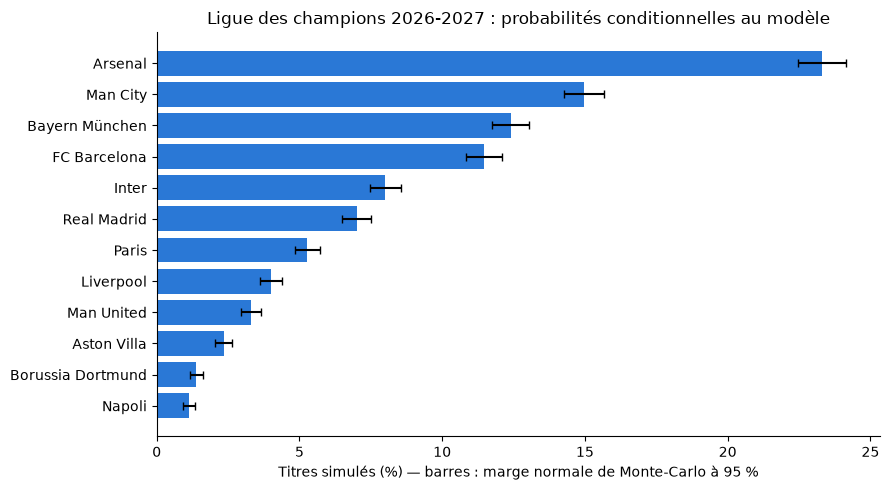

,nom_uefa,pct_titre,repere_consigne_non_contractuel
0,Arsenal,23.30,23–26 %
1,Man City,14.96,environ 15 %
2,Bayern München,12.40,12–13 %
3,FC Barcelona,11.46,environ 12 %


Paris : 37.37 % de top 8 ; repère des consignes : environ 38 %.


In [10]:
meilleurs = resultats.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(meilleurs.nom_uefa, meilleurs.pct_titre, color='#2a78d6',
        xerr=meilleurs.marge_mc95_titre_points_pct, capsize=3)
ax.set_xlabel('Titres simulés (%) — barres : marge normale de Monte-Carlo à 95 %')
ax.set_title('Ligue des champions 2026-2027 : probabilités conditionnelles au modèle')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

# Repères du document : comparaison diagnostique, jamais une cible à reproduire.
reperes = {'Arsenal': '23–26 %', 'Man City': 'environ 15 %', 'Bayern München': '12–13 %', 'FC Barcelona': 'environ 12 %'}
controle_grandeur = resultats.loc[resultats.nom_uefa.isin(reperes), ['nom_uefa', 'pct_titre']].copy()
controle_grandeur['repere_consigne_non_contractuel'] = controle_grandeur.nom_uefa.map(reperes)
display(controle_grandeur.round(2))
psg = resultats.loc[resultats.nom_uefa.eq('Paris')].iloc[0]
print(f'Paris : {psg.pct_top8:.2f} % de top 8 ; repère des consignes : environ 38 %.')

## 8. Points de qualification et finales les plus fréquentes

On mesure les points du **club classé 8e**, puis du **club classé 24e**, dans chaque
saison. Ce sont des distributions, pas des seuils garantis : avec le même nombre de
points, la différence de buts peut décider de la qualification.

,rang,points_moyens,quantile_5pct,mediane,quantile_95pct
0,8,16.04,15,16,17
1,24,9.01,8,9,10


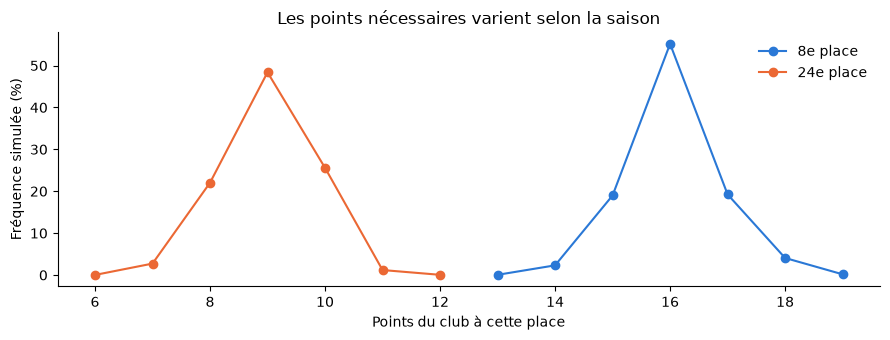

,club_1,club_2,nb_finales,probabilite_pct
0,Arsenal,Man City,680,6.80
1,Arsenal,FC Barcelona,566,5.66
2,Arsenal,Bayern München,522,5.22
3,Arsenal,Inter,414,4.14
4,Bayern München,Man City,366,3.66
5,FC Barcelona,Man City,310,3.10
6,Arsenal,Real Madrid,286,2.86
7,Bayern München,FC Barcelona,269,2.69
8,Man City,Real Madrid,250,2.50
9,Inter,Man City,248,2.48


In [11]:
seuils_lecture = []
distributions_seuils = []
for colonne, rang in enumerate([8, 24]):
    valeurs = simulation['seuils'][:, colonne]
    quantiles = np.quantile(valeurs, [0.05, 0.5, 0.95], method='nearest')
    seuils_lecture.append({'rang': rang, 'points_moyens': valeurs.mean(),
                          'quantile_5pct': quantiles[0], 'mediane': quantiles[1], 'quantile_95pct': quantiles[2]})
    comptes = Counter(valeurs.tolist())
    distributions_seuils.extend({'rang': rang, 'points': points, 'frequence_pct': 100*nombre/NB_SIMULATIONS}
                                for points, nombre in sorted(comptes.items()))
seuils_resume = pd.DataFrame(seuils_lecture)
seuils_distribution = pd.DataFrame(distributions_seuils)
display(seuils_resume.round(2))
fig, ax = plt.subplots(figsize=(9, 3.5))
for rang, couleur in [(8, '#2a78d6'), (24, '#eb6834')]:
    t = seuils_distribution.loc[seuils_distribution.rang.eq(rang)]
    ax.plot(t.points, t.frequence_pct, marker='o', label=f'{rang}e place', color=couleur)
ax.set(xlabel='Points du club à cette place', ylabel='Fréquence simulée (%)', title='Les points nécessaires varient selon la saison')
ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

finales = pd.DataFrame([
    {'club_1': clubs.iloc[a].nom_uefa, 'club_2': clubs.iloc[b].nom_uefa,
     'nb_finales': nombre, 'probabilite_pct': 100*nombre/NB_SIMULATIONS}
    for (a, b), nombre in simulation['finales'].most_common()
])
assert finales.nb_finales.sum() == NB_SIMULATIONS
assert np.isclose(finales.probabilite_pct.sum(), 100)
display(finales.head(10).round(2))

## 9. Backtest : rejouer 2024-2025 et 2025-2026 depuis septembre

Pour chaque saison, le vrai calendrier de ligue est pris dans `games.csv` avec
`competition_id == "CL"` et `round == "Group Stage"`. On utilise le premier Elo
pré-match de chaque participant, sans injecter les résultats de cette saison dans
les simulations. Les quatre fonctions d’apprentissage suivantes sont copiées depuis
`MODEL_POISSON` : le modèle de scores est réentraîné sur les seules saisons précédentes.
Pour 2024-2025, la variable nouveau format est absente ; pour 2025-2026, son effet
peut être appris sur 2024-2025.

**Correction locale d’une fuite connue :** pour les lignes « Elo maison recalé »,
la droite ajustée sur toute la saison est remplacée par un recalage utilisant seulement
les observations officielles de dates strictement antérieures au match. Si elles sont
insuffisantes, on garde l’Elo maison brut, en le signalant. La table EDA d’origine reste intacte.
Les constantes K=20 et H=60 restent celles du groupe : leur choix rétrospectif constitue
une limite résiduelle, ce backtest n’est donc pas un examen entièrement indépendant.

In [12]:
VARIABLES = ['ecart_100', 'terrain']

def lignes_equipes(d):
    # Chaque match devient 2 lignes : une par équipe, vue de son côté
    ecart = d['ecart_elo_complet'].to_numpy() / 100
    terrain = d['domicile'].to_numpy()
    nouveau = d['nouveau_format'].to_numpy()
    lignes = pd.DataFrame({
        'ecart_100': np.concatenate([ecart, -ecart]),               # un écart change de signe selon le côté
        'terrain': np.concatenate([terrain, -terrain]),
        'nouveau_format': np.concatenate([nouveau, nouveau]),       # le format joue pareil pour les deux équipes
    })
    if 'ecart_forme_5' in d:
        forme = d['ecart_forme_5'].to_numpy()
        lignes['ecart_forme_5'] = np.concatenate([forme, -forme])
    if 'buts_dom' in d:
        lignes['buts'] = np.concatenate([d['buts_dom'].to_numpy(), d['buts_ext'].to_numpy()])
    return lignes

def entrainer_poisson(d, variables=VARIABLES):
    lignes = lignes_equipes(d)
    modele = make_pipeline(SimpleImputer(strategy='median'), PoissonRegressor(alpha=0, solver='newton-cholesky', tol=1e-10, max_iter=1000))
    return modele.fit(lignes[variables], lignes['buts'])

def coefficients(modele, variables=VARIABLES):
    regression = modele[-1]
    return pd.Series([regression.intercept_, *regression.coef_], index=['const', *variables])

def buts_attendus_matchs(modele, d, variables=VARIABLES):
    # Buts attendus des deux équipes pour chaque match de d (le Pipeline applique ses propres transformations)
    lam = modele.predict(lignes_equipes(d)[variables])
    return lam[:len(d)], lam[len(d):]

In [13]:
def corriger_recalage_futur(historique):
    """Copie de travail : aucun fichier de Loan/Moussa n'est réécrit."""
    h = historique.copy()
    references = pd.concat([
        h[['date', f'{c}_elo_global', f'{c}_elo_complet', f'{c}_source_elo']]
        .set_axis(['date', 'maison', 'officiel', 'source'], axis=1)
        for c in ['home', 'away']
    ], ignore_index=True)
    references = references.loc[references.source.eq('officiel')].sort_values('date')
    audit = []
    for cote in ['home', 'away']:
        h[f'{cote}_elo_backtest'] = h[f'{cote}_elo_complet']
        indices = h.index[h[f'{cote}_source_elo'].str.contains('recalé', na=False)]
        for indice in indices:
            date = h.at[indice, 'date']
            passe = references.loc[references.date.lt(date)]
            maison = h.at[indice, f'{cote}_elo_global']
            if len(passe) >= 20 and passe.maison.nunique() > 1:
                pente, origine = np.polyfit(passe.maison, passe.officiel, 1)
                valeur = pente * maison + origine
                assert passe.date.max() < date
                methode = 'recalage sur observations strictement antérieures'
            else:
                valeur = maison
                methode = 'Elo maison brut ; références antérieures insuffisantes'
            h.at[indice, f'{cote}_elo_backtest'] = valeur
            audit.append({'game_id': h.at[indice, 'game_id'], 'cote': cote, 'date': date,
                          'elo_initial': h.at[indice, f'{cote}_elo_complet'], 'elo_corrige': valeur,
                          'references_utilisees': len(passe), 'methode': methode})
    h['ecart_elo_backtest'] = h.home_elo_backtest - h.away_elo_backtest
    assert np.isfinite(h[['home_elo_backtest', 'away_elo_backtest']].to_numpy()).all()
    return h, pd.DataFrame(audit)

In [14]:
def preparer_backtest(saison, historique, jeux):
    colonnes = ['game_id', 'round', 'date', 'home_club_id', 'away_club_id',
                'home_club_name', 'away_club_name']
    ligue = jeux.loc[jeux.competition_id.eq('CL') & jeux.season.eq(saison)
                     & jeux['round'].eq('Group Stage'), colonnes].copy()
    assert len(ligue) == 144 and ligue.game_id.is_unique
    premiere_date = ligue.date.min()
    # La cible future n'intervient ni dans le fit ni dans les Elo d'initialisation.
    apprentissage = historique.loc[historique.season.lt(saison)
                                   & historique.date.lt(premiere_date)].copy()
    assert len(apprentissage) > 0 and apprentissage.season.max() < saison
    assert apprentissage.date.max() < premiere_date
    apprentissage['ecart_elo_complet'] = apprentissage.ecart_elo_backtest
    apprentissage['buts_dom'] = apprentissage.dom_j_buts_pour
    apprentissage['buts_ext'] = apprentissage.ext_j_buts_pour
    apprentissage['domicile'] = (~apprentissage.neutre).astype(int)
    apprentissage['nouveau_format'] = apprentissage.season.ge(2024).astype(int)
    variables = ['ecart_100', 'terrain'] + (['nouveau_format'] if saison >= 2025 else [])
    modele = entrainer_poisson(apprentissage, variables)
    coefs = coefficients(modele, variables)
    p = {'intercept': float(coefs['const']), 'coef_ecart_100': float(coefs['ecart_100']),
         'coef_terrain': float(coefs['terrain']),
         'coef_nouveau_format': float(coefs.get('nouveau_format', 0)), 'max_buts': 10}
    assert saison != 2024 or p['coef_nouveau_format'] == 0

    # Les 144 matchs sont joués sur huit journées de 18 rencontres.
    dates_par_match = ligue[['game_id', 'date']].sort_values(['date', 'game_id']).reset_index(drop=True)
    assert dates_par_match.groupby('date').size().cumsum().isin([18, 36, 54, 72, 90, 108, 126, 144]).sum() == 8
    dates_par_match['journee'] = np.arange(144) // 18 + 1
    ligue = ligue.merge(dates_par_match[['game_id', 'journee']], on='game_id', validate='one_to_one')
    ligue['match_id'] = ligue.game_id.map(lambda gid: f'{saison}-reel-{gid}')
    ligue = ligue.rename(columns={'home_club_id': 'domicile_club_id', 'away_club_id': 'exterieur_club_id'})
    vues = []
    correspondances = historique.set_index('game_id')
    assert set(ligue.game_id) <= set(correspondances.index)
    for cote, cote_cal in [('home', 'domicile'), ('away', 'exterieur')]:
        v = ligue[['game_id', 'date', f'{cote_cal}_club_id', f'{cote}_club_name']].copy()
        v.columns = ['game_id', 'date', 'club_id', 'nom_uefa']
        v['elo_initial'] = v.game_id.map(correspondances[f'{cote}_elo_backtest'])
        v['source_elo'] = v.game_id.map(correspondances[f'{cote}_source_elo'])
        vues.append(v)
    premiers = (pd.concat(vues, ignore_index=True).sort_values(['date', 'game_id'])
                .groupby('club_id', as_index=False).first().sort_values('club_id').reset_index(drop=True))
    assert len(premiers) == 36 and premiers.elo_initial.notna().all()
    cal = preparer_calendrier(ligue, premiers)
    provenance = {'saison': saison, 'nb_matchs_apprentissage': len(apprentissage),
                  'derniere_date_apprentissage': str(apprentissage.date.max().date()),
                  'premiere_date_phase_ligue': str(premiere_date.date()),
                  'variables': variables, 'parametres': p}
    return cal, premiers, premiers.elo_initial.to_numpy(float), p, provenance

In [15]:
def clubs_observes(df):
    return set(df.home_club_id) | set(df.away_club_id)


def realite_saison(saison, historique, jeux):
    saison_matchs = jeux.loc[jeux.competition_id.eq('CL') & jeux.season.eq(saison)].copy()
    noms_tours = saison_matchs['round'].str.lower()
    resultat = {}
    for tour, motif in [('huitiemes', r'last 16|round of 16'), ('quarts', 'quarter-finals'),
                         ('demies', 'semi-finals')]:
        resultat[tour] = clubs_observes(saison_matchs.loc[noms_tours.str.contains(motif, regex=True)])
    finale = saison_matchs.loc[noms_tours.eq('final')]
    if len(finale) == 1:
        f = finale.iloc[0]
        resultat['finale'] = {int(f.home_club_id), int(f.away_club_id)}
        assert f.home_club_goals != f.away_club_goals, 'Vainqueur réel de la finale non identifiable.'
        resultat['titre'] = {int(f.home_club_id if f.home_club_goals > f.away_club_goals else f.away_club_id)}
    else:
        assert finale.empty
        # La finale 2026 est absente ; ses finalistes sont observables grâce aux demi-finales.
        demies = saison_matchs.loc[noms_tours.str.contains('semi-finals')].copy()
        assert len(demies) == 4
        scores = historique.set_index('game_id')[['dom_j_buts_pour', 'ext_j_buts_pour']]
        finalistes = set()
        demies['paire'] = [tuple(sorted((d, e))) for d, e in zip(demies.home_club_id, demies.away_club_id)]
        for paire, rencontres in demies.groupby('paire'):
            assert len(rencontres) == 2
            cumul = {cid: 0 for cid in paire}
            cumul_brut = {cid: 0 for cid in paire}
            for m in rencontres.itertuples():
                cumul[m.home_club_id] += scores.at[m.game_id, 'dom_j_buts_pour']
                cumul[m.away_club_id] += scores.at[m.game_id, 'ext_j_buts_pour']
                cumul_brut[m.home_club_id] += m.home_club_goals
                cumul_brut[m.away_club_id] += m.away_club_goals
            if cumul[paire[0]] == cumul[paire[1]]:
                assert cumul_brut[paire[0]] != cumul_brut[paire[1]], 'Demi-finale réelle indécidable.'
                cumul = cumul_brut  # Uniquement pour reconnaître un vrai vainqueur aux tirs au but.
            finalistes.add(max(cumul, key=cumul.get))
        assert len(finalistes) == 2
        resultat['finale'] = finalistes
        # Pas de résultat de titre inventé : cette métrique ne sera pas calculée.
    for tour, nombre in [('huitiemes', 16), ('quarts', 8), ('demies', 4), ('finale', 2)]:
        assert len(resultat[tour]) == nombre, (saison, tour, resultat[tour])
    return resultat


def evaluer_backtest(saison, resultats, observes):
    classement_favoris = resultats.sort_values(['p_quarts', 'club_id'], ascending=[False, True]).head(8)
    trouves = len(set(classement_favoris.club_id) & observes['quarts'])
    lignes = []
    for tour, clubs_reels in observes.items():
        vrai = resultats.club_id.isin(clubs_reels).to_numpy(dtype=float)
        proba = resultats['p_' + tour].to_numpy()
        uniforme = len(clubs_reels) / 36
        brier = float(np.mean((proba - vrai) ** 2))
        brier_uniforme = float(np.mean((uniforme - vrai) ** 2))
        lignes.append({'saison': saison, 'tour': tour, 'brier_simulation': brier,
                       'brier_uniforme': brier_uniforme, 'brier_skill_score': 1 - brier / brier_uniforme,
                       'quart_finalistes_parmi_8_favoris': trouves,
                       'quart_finalistes_attendus_aveugle': 8 * 8 / 36})
    return pd.DataFrame(lignes)

In [16]:
h_backtest, audit_recalage = corriger_recalage_futur(historique)
print(f'{len(audit_recalage)} lignes club-match recalées uniquement avec le passé.')
display(audit_recalage.head(8).round({'elo_initial': 2, 'elo_corrige': 2}))

mesures_backtest = []
details_backtest = []
provenances_backtest = []
for saison in [2024, 2025]:
    cal, clubs_bt, elo_bt, p_bt, provenance = preparer_backtest(saison, h_backtest, jeux)
    print(f'Backtest {saison}-{saison+1} : modèle appris sur {provenance["nb_matchs_apprentissage"]} matchs, '
          f'jusqu’au {provenance["derniere_date_apprentissage"]}.')
    campagne = campagne_simulation(cal, clubs_bt, elo_bt, p_bt, NB_BACKTEST, rng)
    # La vérité n'est consultée qu'après la simulation pour calculer les métriques.
    observes = realite_saison(saison, h_backtest, jeux)
    mesures_backtest.append(evaluer_backtest(saison, campagne['resultats'], observes))
    details_backtest.append(campagne['resultats'].assign(saison=saison))
    provenances_backtest.append(provenance)
backtest = pd.concat(mesures_backtest, ignore_index=True)
display(backtest.round(4))
for saison in [2024, 2025]:
    q = backtest.loc[backtest.saison.eq(saison) & backtest.tour.eq('quarts')].iloc[0]
    display(Markdown(f'**Lecture {saison}-{saison+1} :** {q.quart_finalistes_parmi_8_favoris:.0f}/8 vrais '
                     f'quart-de-finalistes parmi les huit favoris (référence à l’aveugle : '
                     f'{q.quart_finalistes_attendus_aveugle:.2f} en moyenne). Brier quarts : '
                     f'**{q.brier_simulation:.4f}**, contre **{q.brier_uniforme:.4f}** pour la baseline. '
                     + ('La simulation fait mieux sur cette saison.' if q.brier_simulation < q.brier_uniforme
                        else 'La simulation ne bat pas la baseline sur cette saison.')))
assert not ((backtest.saison == 2025) & (backtest.tour == 'titre')).any()
print('Finale 2026 absente : ses finalistes sont déduits des demi-finales ; aucun Brier de titre en 2025-2026.')

81 lignes club-match recalées uniquement avec le passé.


,game_id,cote,date,elo_initial,elo_corrige,references_utilisees,methode
0,2262147,home,2012-09-18,1795.83,1549.80,0,Elo maison brut ; références antérieures insuf...
1,2262156,home,2012-09-19,1849.11,1588.39,14,Elo maison brut ; références antérieures insuf...
2,2262166,home,2012-10-02,1781.17,1776.55,28,recalage sur observations strictement antérieures
3,2262173,home,2012-10-03,1788.15,1787.57,42,recalage sur observations strictement antérieures
4,2262181,home,2012-10-23,1899.88,1807.09,56,recalage sur observations strictement antérieures
5,2262183,home,2012-10-23,1794.29,1795.92,56,recalage sur observations strictement antérieures
6,2262188,home,2012-10-24,1767.75,1786.60,70,recalage sur observations strictement antérieures
7,2262215,home,2012-11-20,1764.72,1780.90,112,recalage sur observations strictement antérieures


Backtest 2024-2025 : modèle appris sur 1494 matchs, jusqu’au 2024-06-01.


2,000/10,000 saisons — 1.2 s


4,000/10,000 saisons — 2.4 s


...

10,000/10,000 saisons — 5.9 s


,saison,tour,brier_simulation,brier_uniforme,brier_skill_score,quart_finalistes_parmi_8_favoris,quart_finalistes_attendus_aveugle
0,2024,huitiemes,0.1940,0.2469,0.2143,6,1.7778
1,2024,quarts,0.1158,0.1728,0.3298,6,1.7778
2,2024,demies,0.0856,0.0988,0.1329,6,1.7778
3,2024,finale,0.0524,0.0525,0.0018,6,1.7778
4,2024,titre,0.0301,0.0270,-0.1134,6,1.7778
5,2025,huitiemes,0.1622,0.2469,0.3429,6,1.7778
6,2025,quarts,0.0993,0.1728,0.4254,6,1.7778
7,2025,demies,0.0780,0.0988,0.2106,6,1.7778
8,2025,finale,0.0364,0.0525,0.3057,6,1.7778


**Lecture 2024-2025 :** 6/8 vrais quart-de-finalistes parmi les huit favoris (référence à l’aveugle : 1.78 en moyenne). Brier quarts : **0.1158**, contre **0.1728** pour la baseline. La simulation fait mieux sur cette saison.

**Lecture 2025-2026 :** 6/8 vrais quart-de-finalistes parmi les huit favoris (référence à l’aveugle : 1.78 en moyenne). Brier quarts : **0.0993**, contre **0.1728** pour la baseline. La simulation fait mieux sur cette saison.

Finale 2026 absente : ses finalistes sont déduits des demi-finales ; aucun Brier de titre en 2025-2026.


Le score de Brier est la moyenne de `(probabilité − résultat observé)²` sur les 36 clubs,
séparément pour chaque tour. Une amélioration par rapport à l’uniforme est utile, mais
ne suffit pas à démontrer une bonne calibration. Les événements sont liés entre clubs
et entre tours ; deux saisons ne forment pas un grand échantillon indépendant.
Les huit favoris sont choisis sur leur probabilité **d’atteindre les quarts**, avant de
regarder la liste réelle. La finale 2026 ne sera pas complétée par une information externe.

## 10. Audit hostile : tenter de réfuter les résultats

Trois vérifications à lire avec leurs vrais résultats :

1. **Casser les règles :** les tests imposent égalités au cumul, prolongation et tirs au but.
   Ils doivent conserver 16/8/4/2/1 qualifiés, sans bonus de buts à l’extérieur ni double update Elo.
2. **Confronter au hasard :** le backtest compare chaque tour à la baseline uniforme.
   Si le Brier se dégrade, on ne prétend pas que la méthode est validée.
3. **Tester l’hypothèse Elo :** refaire la prévision avec l’Elo figé. Une grande différence
   montre une dépendance à cette hypothèse ; une petite différence ne prouve pas qu’elle est vraie.

Les repères des consignes servent à chercher une erreur, pas à ajuster le modèle pour les retrouver.

In [17]:
figee = campagne_simulation(cal_2026, clubs, elo_initial, p, NB_SIMULATIONS,
                            np.random.default_rng(GRAINE), maj_elo=False, progression=False)
sensibilite = resultats[['club_id', 'nom_uefa', 'pct_titre']].merge(
    figee['resultats'][['club_id', 'pct_titre']].rename(columns={'pct_titre': 'pct_titre_elo_fige'}),
    on='club_id', validate='one_to_one')
sensibilite['ecart_points_pct'] = sensibilite.pct_titre - sensibilite.pct_titre_elo_fige
display(sensibilite.sort_values('ecart_points_pct', key=abs, ascending=False).head(10).round(2))
print(f'Écart absolu maximal de probabilité de titre : {sensibilite.ecart_points_pct.abs().max():.2f} points.')
print('Même graine, mais des chemins aléatoires différents : cette différence contient aussi une erreur de Monte-Carlo.')

,club_id,nom_uefa,pct_titre,pct_titre_elo_fige,ecart_points_pct
0,11,Arsenal,23.30,25.69,-2.39
3,131,FC Barcelona,11.46,12.75,-1.29
1,281,Man City,14.96,15.83,-0.87
9,405,Aston Villa,2.34,1.77,0.57
4,46,Inter,8.01,8.50,-0.49
7,31,Liverpool,4.02,3.53,0.49
11,6195,Napoli,1.12,0.69,0.43
6,583,Paris,5.28,4.93,0.35
8,985,Man United,3.29,2.95,0.34
14,383,PSV,0.65,0.31,0.34


Écart absolu maximal de probabilité de titre : 2.39 points.
Même graine, mais des chemins aléatoires différents : cette différence contient aussi une erreur de Monte-Carlo.


**Ce que cet audit ne règle pas :** les buts sont indépendants et la cadence de buts en
prolongation est supposée proportionnelle au temps. Les blessures, transferts et matchs
nationaux futurs sont ignorés. Les Elo de petits clubs sont estimés avec moins de données.
Le modèle et certains réglages ont déjà été discutés à partir des saisons du backtest :
on ne peut pas les présenter comme un test final aveugle. Enfin, la précision de Monte-Carlo
ne mesure pas l’incertitude sur les coefficients. Une prochaine expérience utile serait
un bootstrap des saisons d’apprentissage, en conservant le découpage chronologique.

## 11. Export et bilan vérifié

Le fichier destiné à l’application est `output/resultats_simulation_2026.csv`, une ligne
par club. Les autres sorties conservent les finales, la distribution des points, le backtest
et les paramètres d’exécution. Tous sont régénérables ; aucun CSV ne doit être forcé dans Git.

In [18]:
OUT.mkdir(exist_ok=True, parents=True)
chemins = {
    'resultats': OUT / 'resultats_simulation_2026.csv',
    'finales': OUT / 'finales_probables_2026.csv',
    'seuils': OUT / 'seuils_simulation_2026.csv',
    'backtest': OUT / 'backtest_simulation_2026.csv',
}
resultats.to_csv(chemins['resultats'], index=False, encoding='utf-8-sig')
finales.to_csv(chemins['finales'], index=False, encoding='utf-8-sig')
seuils_distribution.to_csv(chemins['seuils'], index=False, encoding='utf-8-sig')
backtest.to_csv(chemins['backtest'], index=False, encoding='utf-8-sig')
empreintes = {nom: hashlib.sha256((OUT / nom).read_bytes()).hexdigest() for nom in requis}
metadata = {'graine': GRAINE, 'nb_simulations': NB_SIMULATIONS, 'nb_backtest_par_saison': NB_BACKTEST,
            'regles': REGLES, 'modele': p, 'empreintes_sha256_entrees': empreintes,
            'model_source_commit': '65741bd', 'elo_k': 20, 'elo_bonus_domicile': 60,
            'backtests': provenances_backtest, 'nb_recalages_corriges': len(audit_recalage),
            'duree_prevision_secondes': simulation['duree_secondes']}
(OUT / 'simulation_2026_metadata.json').write_text(json.dumps(metadata, ensure_ascii=False, indent=2))
relu = pd.read_csv(chemins['resultats'], encoding='utf-8-sig')
assert len(relu) == 36 and relu.club_id.is_unique and relu.notna().all().all()
assert np.isclose(relu.pct_titre.sum(), 100)
assert np.allclose(relu[['pct_top8', 'pct_barrages', 'pct_elimine_ligue']].sum(axis=1), 100)
assert np.allclose(relu[['p_huitiemes', 'p_quarts', 'p_demies', 'p_finale']].sum(), [16, 8, 4, 2])
assert np.isfinite(backtest[['brier_simulation', 'brier_uniforme', 'brier_skill_score']].to_numpy()).all()
print('Contrôles réussis : 36 clubs, titre total 100 %, 16/8/4/2 qualifiés en moyenne, backtests évalués sans finale inventée.')
for chemin in chemins.values():
    print('Fichier créé :', chemin)
display(Markdown(f'**Bilan :** {favori.nom_uefa} arrive en tête à **{favori.pct_titre:.2f} %** de titres. '
                 f'Les {NB_SIMULATIONS:,} répétitions stabilisent le calcul sous les hypothèses du modèle ; '
                 'elles ne garantissent pas son réalisme. Le backtest et les limites ci-dessus font partie du résultat.'))

Contrôles réussis : 36 clubs, titre total 100 %, 16/8/4/2 qualifiés en moyenne, backtests évalués sans finale inventée.
Fichier créé : ../output/resultats_simulation_2026.csv
Fichier créé : ../output/finales_probables_2026.csv
Fichier créé : ../output/seuils_simulation_2026.csv
Fichier créé : ../output/backtest_simulation_2026.csv


**Bilan :** Arsenal arrive en tête à **23.30 %** de titres. Les 10,000 répétitions stabilisent le calcul sous les hypothèses du modèle ; elles ne garantissent pas son réalisme. Le backtest et les limites ci-dessus font partie du résultat.